**Projektfrage:** Kann ein kleines neuronales Netz künstlich maskierte Lücken in täglichen Meerestemperaturdaten besser rekonstruieren als einfache Baselines?

**Hintergrund des Projekts:** Erdbeobachtungsdaten sind selten vollständig. Mal fallen Sensoren aus, oder Wolken verdecken die Sicht. Ein sinnvoller Umgang mit fehlenden Daten ist daher unabdingbar. Mit dem Problem, fehlende Daten sinnvoll zu rekonstruieren, befassen wir uns daher in diesem Projekt.

**Die Daten:** Grundlage dieses Projekts ist der Datensatz "SST, Daily Optimum Interpolation (OI), AVHRR Only, Version 2.1, Final, Global,
0.25°, 1981-present, Lon+/-180" des "NOAA NCEI". Dies ist ein vollständiger Datensatz mit täglichen Messungen von Meerestemperaturen, die zu einem lückenlosen Gitter interpoliert worden sind. Wir werden künstlich Daten löschen, um diese mithilfe eines neuronalen Netzes zu rekonstruieren. Bei den künstlichen Lücken handelt es sich also nicht um echte Satellitenlücken, da die ursprünglichen Daten selbst interpoliert sind.
Da die korrekten Daten vorliegen, können wir diese nutzen, um den Erfolg unseres Netzes zu messen.

**Mathematische Formulierung:**

*  $\Omega$ : Menge der Meerespunkte des Gitters
*   $t$ : Tag
*   $x_{t}$ : Temperaturfeld, genauer: ein Gitter aus Breite $\times$ Länge
*   $m_{t}$ : Maske mit Werten aus $\{0,1\}$, die aussagen, ob ein Gitterpunkt vorhanden ist (1) oder fehlt (0).
*   f : das Modell, welches teilweise sichtbare Felder als Input bekommt und das vervollständigte Feld $\hat{x}_t$ ausgeben soll.

Der Fehler (die Lossfunktion) wird anschließend nur auf den fehlenden Meerespunkten, um den Erfolg des Modells zu messen. Wir trainieren hierfür den MSE und nutzen für die Auswertung dessen Wurzel, den RMSE, da dieser Wert in °C interpretierbar ist. Die Güte des Modells wird anhand des RMSE im Jahr 2022 gemessen (unserem Testjahr).

**Wichtige Bausteine:**

*   Wir konzentrieren uns auf den Zeitraum 2018-2022 und den Bereich mit Koordinaten 53–60°N, 3–15°O.
*  Im Laufe des Projekts werden wir 30% der Punkte künstlich verstecken und diese durch das neuronale Netz versuchen zu rekonstruieren.
*  Baselines: werden später definiert und hier erklärt
* Zeitlicher Split:
  * Training: Daten aus 2018-2020
  * Validierung: Daten aus 2021
  * Test: Daten aus 2022



Im Folgenden installieren wir ein wichtiges Paket:

In [ ]:
!pip install netcdf4 pydap # Pakete, um Dateiformat NetCDF zu lesen und diese aus der URL zu holen.

Datensatz öffnen (nur am Anfang wichtig, später, wenn das einmal durchgelaufen ist und die Datei im Google Drive gespeichert it, können die folgenden 2 Zellen weggelassen werden):

In [ ]:
import xarray as xr #Paket, welches hilfreich ist, um mit mehrdimensionalen, gelabelten Arrays zu arbeiten.

url = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/ncdcOisst21Agg_LonPM180" #URL, in der der Datensatz zur Verfügung steht.
ds = xr.open_dataset(url) #öffnet die url
print(ds) #gibt uns die Informationen über das Dataset ds aus

<xarray.Dataset> Size: 253GB
Dimensions:    (time: 15260, zlev: 1, latitude: 720, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 122kB 1981-09-01T12:00:00 ... 2026-09-20...
  * zlev       (zlev) float32 4B 0.0
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
Data variables:
    sst        (time, zlev, latitude, longitude) float32 63GB ...
    anom       (time, zlev, latitude, longitude) float32 63GB ...
    err        (time, zlev, latitude, longitude) float32 63GB ...
    ice        (time, zlev, latitude, longitude) float32 63GB ...
Attributes: (12/47)
    _NCProperties:              version=2,netcdf=4.8.1,hdf5=1.10.7
    cdm_data_type:              Grid
    comment:                    Data was converted from NetCDF-3 to NetCDF-4 ...
    Conventions:                CF-1.6, ACDD-1.3, COARDS
    creator_email:              oisst-help@noaa.gov
    creator_name:  

Wir fokussieren uns auf einen Ausschnitt (Nordsee und westliche Ostsee, fünf Jahre) und speichern ihn:

In [ ]:
sst = ds["sst"].sel(
    time=slice("2018-01-01", "2022-12-31"),
    latitude=slice(53, 60),
    longitude=slice(3, 15),
).isel(zlev=0).load()
# sst ist der Name des Ausschnitts des Datasets, den wir uns näher anschauen wollen
# ds["sst"] wählt die Variable Meerestemperatur aus dem Dataset ds aus
# .sel(...) gibt an, dass wir die Werte über die Achsen (Datum, Grad) auswählen wollen, nicht über ihre Position.
# die nächsten 3 Zeilen geben an, welche Werte wir ausschneiden und behalten wollen. Zeitlich schränken wir uns auf die Jahre 2018-2022 ein, und von den Koordinaten her auf die Bereiche 53-60° N und 3-15° O.
# .isel(zlev=0) wählt über Position die Tiefenachse zlev aus. Da diese überall den gleichen Eintrag hat, nämlich dass wir uns an der Meeresoberfläche befinden, lassen wir die durch =0 einfach weg.
# .load() lädt die Daten so wie wir sie gerade angepasst haben, in den Arbeitsspeicher runter. Somit brauchen wir dann den Server nicht mehr.
print(sst.shape)

from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive

sst.to_netcdf("/content/drive/MyDrive/sst_nordsee_ostsee.nc") # Speichert die Daten permanent in Google Drive

# Alte Version: sst.to_netcdf("sst_nordsee_ostsee.nc") # Speichert die Daten als Datei ab, sodass diese nicht immer wieder neu geladen werden müssen. Diese Datei ist allerdings nur temporär gespeichert, solange die Sitzung löuft.

(1823, 28, 48)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MyDrive


Nachdem die obere Zelle einmal ausgeführt wurde, ist die Datei sst im Google Drive gespeichert und die Zelle kann ab jetzt übersprungen werden. Ab jetzt laden wir die Daten hierüber:

In [ ]:
import xarray as xr
sst = xr.open_dataarray("/content/drive/MyDrive/sst_nordsee_ostsee.nc")

Daten visualisieren:

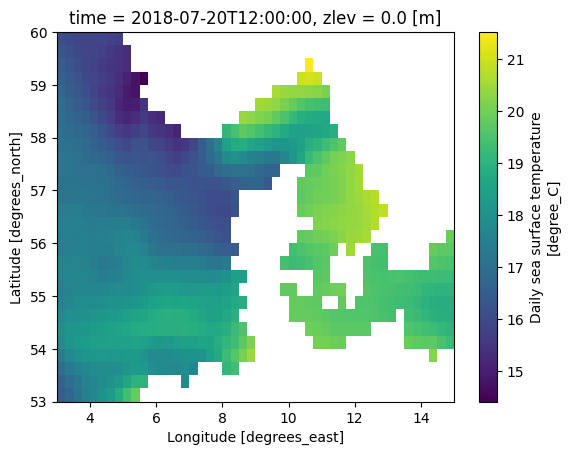

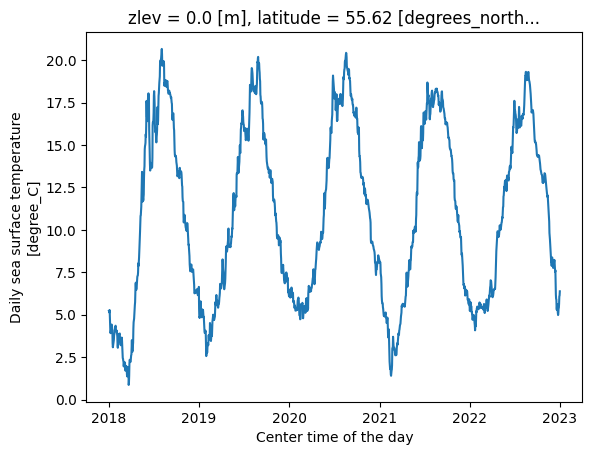

Anteil der leeren Felder an Land:
0.4382440476190476


In [ ]:
import matplotlib.pyplot as plt

sst.isel(time=200).plot()                    # Karte eines Tages an Position 200 (das ist der 20.7.2018). isel sagt wieder aus, dass wir über die Position auswählen. Das Gitter zeigt dann den Ausschnitt in dem Ausgewählten Bereich und die Farbe visualisiert die Temperatur. Die weißen Punkte sind Landpunkte, an denen korrekterweise keine Information vorliegt (NaN).
plt.show()
sst.isel(latitude=10, longitude=20).plot()   # Zeitreihe eines Punktes. Hier wird also nur ein Punkt ausgewählt, während die Temperatur über den Verlauf der Zeit gezeigt wird.
plt.show()
print("Anteil der leeren Felder an Land:")
print(float(sst.isnull().mean()))            # Anteil leerer Felder (Land)

**Beobachtungen zu den Daten:** Zunächst fällt in dem ersten Plot auf, dass die Temperaturen in der Bucht (umgeben von Landflächern) tendenziell höher sind, als im offenen Meer. Außerdem scheint es einen Trend zu geben, dass die Temperaturen kühler werden, je weiter nördlich man sich befindet, zumindest im offenen Meer. Im zweiten Grafen können wir erkennen, wie die Meerestemperatur zyklisch mit den Jahreszeiten schwankt. Besonders kühl scheint es in 2021 gewesen zu sein.

**Split in Trainings-, Validierungs- und Testdaten:**

In [ ]:
sst_train = sst.sel(time=slice("2018-01-01", "2020-12-31"))
print(sst_train.shape)
print(sst_train.time.values[0])
print(sst_train.time.values[-1])

sst_val = sst.sel(time=slice("2021-01-01", "2021-12-31"))
print(sst_val.shape)
print(sst_val.time.values[0])
print(sst_val.time.values[-1])

sst_test = sst.sel(time=slice("2022-01-01", "2022-12-31"))
print(sst_test.shape)
print(sst_test.time.values[0])
print(sst_test.time.values[-1])

(1096, 28, 48)
2018-01-01T12:00:00.000000000
2020-12-31T12:00:00.000000000
(363, 28, 48)
2021-01-01T12:00:00.000000000
2021-12-31T12:00:00.000000000
(364, 28, 48)
2022-01-01T12:00:00.000000000
2022-12-31T12:00:00.000000000


Hier hat sich herausgestellt, dass Tage fehlen. Also müssen wir im nächsten Schritt herausfinden, welche das sind.

In [ ]:
import pandas as pd
all_days = pd.date_range("2018-01-01", "2022-12-31", freq="D") #erzeugt die Liste aller Tage, die da sein sollten
sst_days = pd.DatetimeIndex(sst.time.values).normalize() #macht aus den Zeitstempeln reine Tage, damit der Vergleich funktioniert.
all_days.difference(sst_days) #gibt die Einträge aus all_days zurück, die in sst_days nicht vorkommen

DatetimeIndex(['2021-03-23', '2021-09-07', '2022-10-19'], dtype='datetime64[ns]', freq=None)

Die fehlenden Tage sind der 23.3.2021, der 7.9.2021 und der 19.10.2022. Der Grund hierfür ist unklar, es könnten fehlende Daten im ursprünglichen Datensatz sein, oder beim Laden vom Server könnte etwas verloren gegangen sein. Da aber jeder Tag hier einzeln bearbeitet wird, ist es nicht weiter schlimm, diese Tage einfach wegzulassen.

Nun wollen wir die Maske erstellen, um Land- und Meeresgitterpunkte unterscheiden zu können.

(28, 48)
0.43824404761904767
True


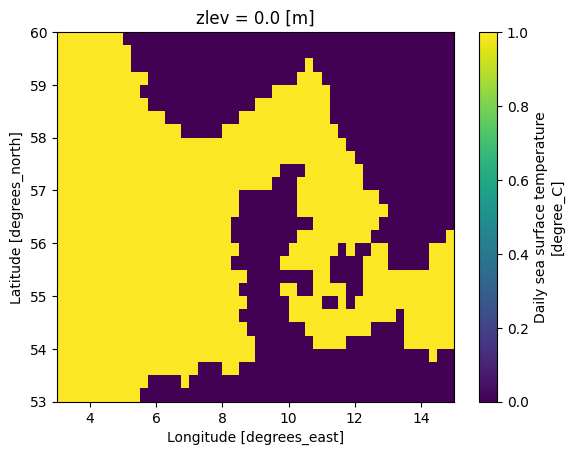

In [ ]:
ocean = sst.notnull().any("time")
print(ocean.shape)                         # stimmt mit den hinteren beiden Koordinaten von sst überein, also der Länge und Breite des Ausschnitts, den wir betrachten
print(float(1 - ocean.mean()))             # Stimmt mit dem Landanteil überein, den wir schon vorher geprüft haben
print(bool((ocean == sst.notnull().all("time")).all()))  # Hiermit prüfen wir, ob durch .any und .all dieselben Punkte aussortiert werden. Falls ja (was hier der Fall ist) wissen wir, dass jeder Meerespunkt auch wirklich alle Daten enthält und dass wir nicht fälschlicherweise Mischpunkte als Landpunkte auffassen, nur weil dabei Daten fehlen.
ocean.plot()

Als nächstes generieren wir die Maske mit fehlenden Werten. Diese werden zufällig gewählt und mit einer Schwelle (hier: 30%) wählen wir aus, wie groß der Anteil von fehlenden Werten sein soll.

In [ ]:
import numpy as np

rng = np.random.default_rng(42) # Zufallsgenerator mit Seed, sodass er jedes Mal dieselben Werte generiert.
map_random = rng.random(sst.shape) #Wir geben jedem Gitterpunkt einen random Wert zwischen 0 und 1
hidden_np = (map_random < 0.3) & ocean.values #Wir setzen 30% aller Meerespunkte auf wahr (die werden versteckt) und gleichen sie auch noch mit oceans ab. So stellen wir sicher, dass nur Meerespunkte wahr sein können.

hidden = xr.DataArray(hidden_np, coords=sst.coords, dims=sst.dims) #Wir wollen aus unserem Numpy Array wieder ein xarray-Objekt machen mit den gleichen Koordinaten und Dimensionen wie sst.
sst_masked = sst.where(~hidden) #hier wenden wir nun hidden auf sst an und verstecken 30% der Meeresdaten. .where() behält nur die Werte, die die Bedingung (nicht hidden) erfüllen und setzt alle anderen Werte in sst auf NaN.




Ein paar Dinge wollen wir kontrollieren, um sicherzustellen, dass wir mit dem richtigen Setup weiterarbeiten:

In [ ]:
print(hidden.values.mean()) # Anteil aller versteckten Gitterpunkte, erwartet: 0,3 * 0,56 = ca. 0,17

0.16854576443852362


In [ ]:
print(hidden.values[:, ocean.values].mean()) # Anteil der versteckten Meerespunkte, erwartet: ca. 0.3

0.3000337846428818


In [ ]:
print((hidden.values & ~ocean.values).sum()) # Anzahl der Landpunkte, die wir versteckt haben, erwartet: 0

0


In [ ]:
def make_hidden(seed): # Funktion zum Testen der Reproduzierbarkeit
    rng = np.random.default_rng(seed)
    rand = rng.random(sst.shape)
    return (rand < 0.3) & ocean.values

a = make_hidden(42)
b = make_hidden(42)
c = make_hidden(7)

print(np.array_equal(a, b))                 # erwartet: True (gleicher Seed)
print(np.array_equal(a, c))                 # erwartet: False (anderer Seed)
print(np.array_equal(a, hidden.values))     # erwartet: True (Vergleich mit unserer ursprünglichen Maske, d.h. diese ist reproduzierbar)

True
False
True


Optischer Vergleich der Karte mit und ohne Löcher: Hier prüfen wir, ob die Löcher tatsächlich zufällig verteilt sind.

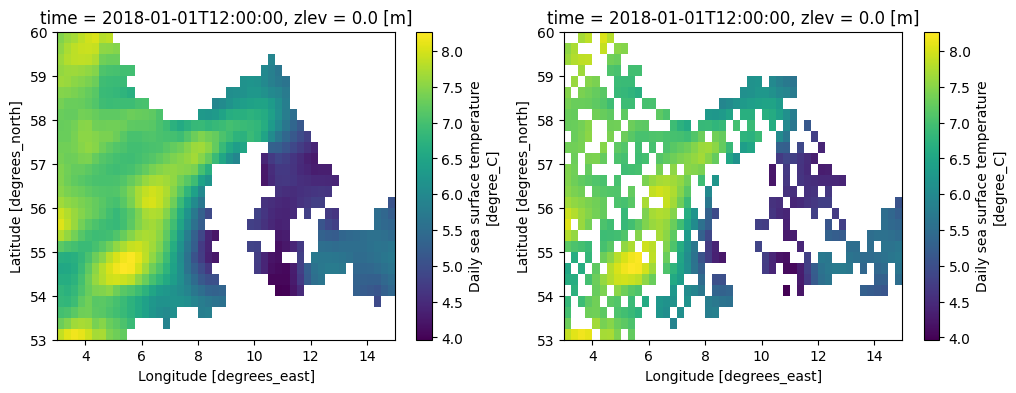

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4)) # gibt die Struktur des Grafen an, nämlich dass wir ihn in 2 Subplots unterteilen
sst.isel(time=0).plot(ax=ax[0]) # Erster Subplot
sst_masked.isel(time=0).plot(ax=ax[1]) # Zweiter Subplot
plt.show()



---

Durch die Schritte oben haben wir einige wichtige Werkzeuge erstellt und diese getestet. Um nicht all diese Zellen jedes Mal durchführen zu müssen (einige sind auch gar nicht mehr wichtig), fassen wir die Codezeilen, die wir im weiteren Verlauf immer wieder brauchen werden, in einer Zeile zusammen:


In [1]:
!pip install netcdf4 pydap # Pakete, um Dateiformat NetCDF zu lesen und diese aus der URL zu holen.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from google.colab import drive
drive.mount('/content/drive')

sst = xr.open_dataarray("/content/drive/MyDrive/sst_nordsee_ostsee.nc").load() #Load holt die Daten in den Arbeitsspeicher und gibt die Datei frei. Sonst kann ein späteres Überschreiben der Datei einen Fehler auslösen.

sst_train = sst.sel(time=slice("2018-01-01", "2020-12-31"))
sst_val = sst.sel(time=slice("2021-01-01", "2021-12-31"))
sst_test = sst.sel(time=slice("2022-01-01", "2022-12-31"))

ocean = sst.notnull().any("time") #Maske über dem gesamten Gitter. Hier meint True, dass der Punkt ein Meerespunkt ist und False dass es ein Landpunkt ist.

rng = np.random.default_rng(42) # Zufallsgenerator mit Seed, sodass er jedes Mal dieselben Werte generiert.
map_random = rng.random(sst.shape) #Wir geben jedem Gitterpunkt einen random Wert zwischen 0 und 1
hidden_np = (map_random < 0.3) & ocean.values #Wir setzen 30% aller Meerespunkte auf wahr (die werden versteckt) und gleichen sie auch noch mit oceans ab. So stellen wir sicher, dass nur Meerespunkte wahr sein können.

hidden = xr.DataArray(hidden_np, coords=sst.coords, dims=sst.dims) #Wir wollen aus unserem Numpy Array wieder ein xarray-Objekt machen mit den gleichen Koordinaten und Dimensionen wie sst. True bedeutet hier versteckt und False vorhanden.
sst_masked = sst.where(~hidden) #hier wenden wir nun hidden auf sst an und verstecken 30% der Meeresdaten. .where() behält nur die Werte, die die Bedingung (nicht hidden) erfüllen und setzt alle anderen Werte in sst auf NaN.

hidden_train = hidden.sel(time=slice("2018-01-01", "2020-12-31"))
hidden_val = hidden.sel(time=slice("2021-01-01", "2021-12-31"))
hidden_test = hidden.sel(time=slice("2022-01-01", "2022-12-31"))

sst_masked_train = sst_masked.sel(time=slice("2018-01-01", "2020-12-31"))
sst_masked_val = sst_masked.sel(time=slice("2021-01-01", "2021-12-31"))
sst_masked_test = sst_masked.sel(time=slice("2022-01-01", "2022-12-31"))






   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.3/118.3 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 4.6 MB/s eta 0:00:00
Mounted at /content/drive


Um erneut zu prüfen, dass diese Zelle die erwünschten Ergebnisse liefert, führen wir noch die nächste Zelle aus:

In [2]:
print(sst.shape)                                              # erwartet (1823, 28, 48)
print(sst_train.shape[0] + sst_val.shape[0] + sst_test.shape[0])   # erwartet 1823
print(hidden_val.shape == sst_val.shape)                      # erwartet True
print(float(hidden.where(ocean).mean()))                      # erwartet ca. 0.30

(1823, 28, 48)
1823
True
0.3000337846428818


Nun wollen wir die RMSE Funktion schreiben. Diese nutzen wir, um den Fehler und damit die Güte unseres Modells zu messen. Um diese mit einem kleinen Beispiel zu testen, definieren wir erstmal eine kleine Version der Input-Parameter pred (unsere Vorhersage), truth (die tatsächlichen Werte, die wir versteckt haben) und hidden (die Maske, die uns angibt, welche Werte versteckt werden).

In [3]:
import xarray as xr
import numpy as np

pred_bsp = xr.DataArray([[1, 2], [3, 4]], dims=("x", "y"))
truth_bsp = xr.DataArray([[2, 1], [4, 3]], dims=("x", "y"))
hidden_bsp = xr.DataArray([[False, True], [False, True]], dims=("x", "y"))

In [4]:
def rmse(pred, truth, hidden):
  if (pred.isnull() & hidden).any():
    raise ValueError("Prediction has a NaN at a hidden point. This makes the RMSE appear better than it actually is.")
  error = float(np.sqrt(((pred - truth)**2).where(hidden).mean()))
  return(error)




Die Funktion oben hat den Test mit den 2x2 Feldern bestanden. Wir haben außerdem eine Fehlermeldung eingebaut, die den Nutzer warnt, wenn die Vorhersage NaN Werte enthält und der RSME dadurch fälschlicherweise besser wird. Nun ist es Zeit für weitere Tests mit den Dimensionen, mit denen wir tatsächlich arbeiten.

In [5]:
const = float(sst_train.mean())
pred_const = xr.full_like(sst_val, const)

print(const)                                         # Mittelwert in °C
print(rmse(pred_const, sst_val, hidden_val))         # RMSE der konstanten Vorhersage
print(float(sst_val.where(hidden_val).std()))        # Streuung der Wahrheit an den versteckten Punkten

print(rmse(sst_val, sst_val, hidden_val))            # erwartet 0.0, testen den Fehler mit den richtigen Werten

pred_nan = pred_const.where(~hidden_val)             # an versteckten Punkten NaN
rmse(pred_nan, sst_val, hidden_val)                  # erwartet: ValueError

11.028787612915039
4.901219796143844
4.8975677490234375
0.0


ValueError: Prediction has a NaN at a hidden point. This makes the RMSE appear better than it actually is.

Der die Vorhersage `pred_const` mit ihrem RMSE `rmse(pred_const, sst_val, hidden_val) = 4.901219796143844` ist unsere erste Baseline, die es durch das neuronale Netz zu schlagen gilt. Die zweite Baseline, die vermutlich einen kleineren RMSE haben wird, ermitteln wir mithilfe der Klimatologie. Die Idee hier ist, dass wir nicht einfach den Mittelwert über alle Tage und Jahreszeiten als Vorhersage nutzen, sondern für jeden Tag des Jahres den Mittelwert über die verschiedenen Jahre nehmen. Wir schauen also für jeden einzelnen Tag, was der durchschnittliche Wert im Test-Zeitraum war und nutzen diesen Wert für unsere Vorhersage.

Zunächst vereinfachen wir unsere Daten allerdings noch. Da 2020 ein Schaltjahr war, hat es einen Tag mehr als alle anderen Jahre. Würden wir den 29.2.2020 behalten, würden sich die Werte danach jeweils um einen Tag verschieben. Der Fehler, der hierdurch entsteht, ist zwar voraussichtlich sehr klein, cleaner ist es aber, den 29.2.2020 zu entfernen. Dies machen wir mithilfe des folgenden Codes.

In [6]:
ist_29_2 = (sst_train.time.dt.month == 2) & (sst_train.time.dt.day == 29) #Vektor der Länge 1096 (Anzahl der Tage aus dem Trainingszeitraum 2018-2020) mit False überall außer an der Stelle des 29.2.2020, da steht True
sst_train_365 = sst_train.isel(time=~ist_29_2.values) # Einschränkung von sst_train auf alle Tage außer den 29.2.2020
sst_masked_train_365 = sst_masked_train.isel(time=~ist_29_2.values)
hidden_train_365 = hidden_train.isel(time=~ist_29_2.values)

md_train = sst_train_365.time.dt.strftime("%m-%d") # sst_train_365.time ist die Zeitachse von sst_train_365. .dt (steht für datetime) ermöglicht es uns, einzelne Teile des Datums als solche zu bearbeiten. strftime("%m-%d") macht aus jedem Datum einen Text, z. B. "03-01" für den 1. März. Dieser Text ist unabhängig vom Jahr.
sst_train_365 = sst_train_365.assign_coords(md=md_train) # durch assign_coords(md=...) wird die Liste md_train als zusätzliche Beschriftung an die Zeitachse gehängt.

clim = sst_train_365.groupby("md").mean("time") # Gruppiert die Daten erst, sodass in jeder Gruppe genau ein und derselbe Jahrestag aus 2018, 2019 und 2020 ist. Durch mean("time") wird dann die durchschnittliche Temperatur für jeden Tag im Jahr berechnet.

md_val = sst_val.time.dt.strftime("%m-%d") #Dasselbe, was wir bei md_train gemacht haben, setzen wir jetzt für unsere Validierungsdaten aus 2021 um. Wie wir schon oben herausgefunden haben, fehlen in 2021 die Tage 23.03. und 07.09..

pred_clim = clim.sel(md=md_val).drop_vars("md") #Hier wird clim durch .sel(md=md_val) so angepasst, dass es genau die Tage enthält, die für 2021 vorliegen. .drop_vars("md") löscht anschließend die überflüssig gewordene Beschriftung.


Durch den folgenden Vergleich prüfen wir, dass die Zuordnung von clim und die Werte in 2021 (den Validierungsdaten) geklappt hat:

In [7]:
print(sst_train.shape[0], sst_train_365.shape[0])        # erwartet 1096 und 1095
print(clim.shape)                                        # erwartet (365, 28, 48)
print(pred_clim.shape)                                   # erwartet (363, 28, 48)
print(bool((pred_clim.time == sst_val.time).all()))      # erwartet True, gleicht ab, dass wir hier immer die gleichen Tage miteinander vergleichen.

1096 1095
(365, 28, 48)
(363, 28, 48)
True


In der folgenden Grafik sehen wir den Vergleich zwischen den Werten aus dem Klimatologie-Ansatz und den wahren Werten. Besonders schlecht passen die Werte im März zusammen, da dieser offenbar kälter war als in den Jahren zuvor. Besonders gut dagegen passen die Werte im November zusammen.

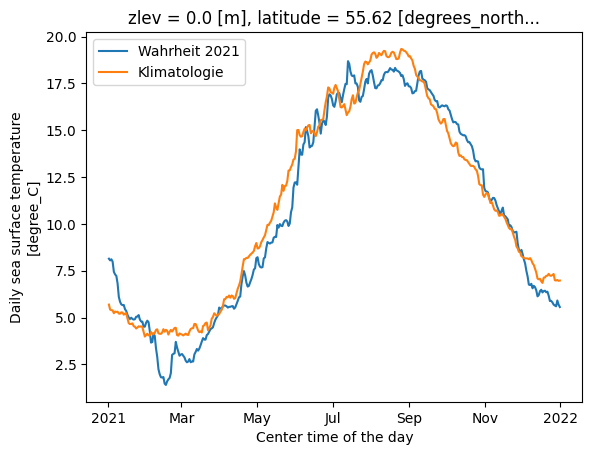

In [8]:
punkt = dict(latitude=10, longitude=20)
sst_val.isel(**punkt).plot(label="Wahrheit 2021")
pred_clim.isel(**punkt).plot(label="Klimatologie")
plt.legend()
plt.show()

In der nächsten Zelle berechnen wir nun den RSME für diesen Klimatologie-Ansatz:

In [9]:
print(rmse(pred_clim, sst_val, hidden_val))

1.0791794968852482


Unsere Ergebnisse wollen wir in einem Directory speichern, um später alle Werte an einem Ort gespeichert zu haben und somit eine bessere Übersicht zu schaffen.

In [10]:
ergebnisse = {}
ergebnisse["konstanter Durchschnittswert, Val 2021"] = rmse(pred_const, sst_val, hidden_val)
ergebnisse["Klimatologie, Val 2021"] = rmse(pred_clim, sst_val, hidden_val)
print(ergebnisse)

{'konstanter Durchschnittswert, Val 2021': 4.901219796143844, 'Klimatologie, Val 2021': 1.0791794968852482}


Bevor wir das neuronale Netz bauen und trainieren, rufen wir uns noch einige wichtige Informationen ins Gedächtnis.
Ein Tensor ist Pytorches Äquivalent zu einem Array in Numpy. Eine wichtige Eigenschaft von Tensoren, die wir uns in diesem Projekt zunutze machen, ist dass sie Gradienten automatisch nachverfolgen (tracken) und somit das maschinelle Lernen ermöglichen. Sie sind außerdem kompatibel mit GPUs, was unser Training beschleunigt. Man kann jedoch einen Tensor in einen Array umformen und umgekehrt.

Die Form unseres Eingabe-Tensors `(X_train, X_val)`, auf welchem wir das Netz trainieren und validieren, ist gegeben durch (N, C, H, W). Dabei gibt N die Anzahl der Tage an (1095 für die Trainingsdaten und 363 für die Validierung), C die Informationen, die zu jedem einzelnen Punkt vorhanden sind (wir nennen sie Kanäle und es sind die Angaben zur Temperatur, Sichtbarkeit und ob es sich um einen Meerespunkt handelt). H entspricht den 28 Breitengraden und W den 48 Längengraden.

Ein wichtiger Schritt zur Vorbereitung ist die Normalisierung unserer Daten. Da Netze stabiler lernen, wenn die Zahlen um 0 liegen und eine Streuung von etwa 1 haben, werden wir ihren Mittelwert abziehen und durch die Standardabweichung teilen. Hierbei nutzen wir ausschließlich den Mittelwert und die Standardabweichung aus den Trainingsdaten, da wir sonst ein Datenleck erzeugen würden. Anschließend müssen wir, um den korrekten RMSE in °C zu bestimmen, die Normalisierung wieder rückgängig machen, wir multiplizieren also wieder mit der Standardabweichung und addieren den Mittelwert.

Da unser Netz vor allem mit den Operatoren $+$ und $*$ arbeitet, würden sich einzelne NaN Werte durch das gesamte Netz ziehen und dadurch Informationen vernichten. Daher müssen wir noch einen sinnvollen Umgang mit NaN-Werten festlegen, um ein brauchbares Netz zu erzeugen.

Unser Ansatz sieht vor, diese Werte durch den Wert 0 zu ersetzen. Da wir in dem Netz mit normalisierten Werten rechnen, entspricht die 0 hier einem neutralen Wert, der die Informationen weder in die eine (zu kalt) noch die andere Richtung (zu warm) verzerrt. Durch die Kanäle 2 und 3 liefern wir dem Netz die notwendigen Informationen darüber, ob es sich bei einem Punkt um einen sichtbaren Meerespunkt handelt (im Fall $[1,1]$), einen versteckten Meerespunkt, der vorhergesagt werden soll (im Fall $[0,1]$) oder ob es ein Landpunkt ist, der für dieses Modell keine Rolle spielt (im Fall $[0,0]$). (Der Fall $[1,0]$ ist hier per Konstruktion ausgeschlossen). Durch diese Information kann das Netz eine 0 sinnvoll einordnen.

Der Output des Netzes soll ein vollständiges normalisiertes Temperaturfeld sein. Seine Güte wird nur anhand der versteckten Meerespunkte bewertet, wofür wir bereits eine separate Maske definiert haben.

Zunächst definieren wir den Mittelwert und die Standardabweichung unserer Trainingsdaten. Diese nutzen wir später sowohl für die Normalisierung der Trainings- als auch der Validierungsdaten.

In [11]:
mu_train = float(sst_train_365.mean()) # Mittelwert ohne den 29.2.
sd_train = float(sst_train_365.std()) # Standardabweichung ohne den 29.2.
print(float(((sst_train_365 - mu_train) / sd_train).mean())) # Zur Kontrolle: Mittelwert der normalisierten Daten, erwartet: 0
print(float(((sst_train_365 - mu_train) / sd_train).std())) # Zur Kontrolle: Standardabweichung der normalisierten Daten, erwartet: 1

-0.00010364769696025178
1.000035285949707


Durch die folgende Funktion wollen wir unsere Input Daten X_val vorbereiten, die wir später an unser neuronales Netz übergeben werden. Die Inputparameter dieser Funktion sind unsere maskierten Daten, in denen wir NaN auf 0 setzen (dadurch werden dann die anderen Masken wichtig, damit das Netz eine 0 richtig interpretieren kann), die Masken, die Angeben, ob ein Punkt versteckt ist und ob es sich um einen Punkt im Ozean oder an Land handelt, sowie den Mittelwert mu und die Standardabweichung sd, die wir zur Normalisierung benötigen.

In [12]:
import torch

def make_input(sst_masked_part, ocean, mu, sd):
  temp = ((sst_masked_part - mu) / sd).fillna(0).values.astype("float32") # Hier normalisieren wir die Werte aus sst_masked_part, füllen die NaN Werte mit Nullen und machen temp zu einem Array mit float32 Werten.
  visible = sst_masked_part.notnull().values.astype("float32") # Hier definieren wir eine Maske der sichtbaren Meerespunkte. Die Information aus hidden ist bereits in sst_masked_part enthalten, weshalb wir diese Maske hier nicht als Inputparameter benötigen.
  ocean_applied = np.broadcast_to(ocean.values, sst_masked_part.shape).astype("float32") # Hier broadcasten wir die ocean Maske über die Zeitachse von sst_masked_part, sodass sie später für unseren stack die richtige Form hat.
  stack = np.stack([temp, visible, ocean_applied], axis=1) # Nun stapeln wir unsere Daten zusammen
  stack_tensor = torch.from_numpy(stack) # Hier formen wir die Daten aus stack in einen Tensor um.
  return stack_tensor



Nun testen wir diese Funktion:

In [13]:
X_val = make_input(sst_masked_val, ocean, mu_train, sd_train)
print(X_val.shape)                        # erwartet torch.Size([363, 3, 28, 48])
print(X_val.dtype)                        # erwartet torch.float32
print(bool(torch.isnan(X_val).any()))     # erwartet False, die haben wir ja zu 0 umgeformt in unserer Funktion.
print(float(X_val[:, 1].mean()))          # erwartet ca. 0.39, Anteil der sichtbaren Punkte in unserem Gitter
print(float(X_val[:, 2].mean()))          # erwartet ca. 0.56, Anteil der Meeresgitterpunkte

torch.Size([363, 3, 28, 48])
torch.float32
False
0.392812043428421
0.5617559552192688


Die Funktion `make_input` hat unseren Test bestanden. Kommen wir nun zu den Funktionen `make_target` und `make_loss_mask`.

In [14]:
def make_target(sst_part, mu, sd): # Hier nutzen wir nicht mehr sst_masked_part, weil hier ja die versteckten Punkte vorliegen sollen.
  y = ((sst_part - mu) / sd).fillna(0).values.astype("float32")
  return torch.from_numpy(y)[:, None] # umwandeln in einen Tensor und Anfügen einer Kanalachse an Position 1

def make_loss_mask(hidden_part):
    return torch.from_numpy(hidden_part.values.astype("float32"))[:, None]      # wandeln unsere Maske von einem Numpy Array zu einem Tensor um und fügen wieder eine Kanalachse an Position 1 an.


Nun erstellen wir mithilfe dieser 3 Funktionen unsere Daten für das neuronale Netz.

In [15]:
X_train = make_input(sst_masked_train_365, ocean, mu_train, sd_train)
y_train = make_target(sst_train_365, mu_train, sd_train)
m_train = make_loss_mask (hidden_train_365)

X_val = make_input(sst_masked_val, ocean, mu_train, sd_train)
y_val = make_target(sst_val, mu_train, sd_train)
m_val = make_loss_mask(hidden_val)

Anschließend testen wir, ob sie die erwarteten Formen haben und ob die Normalisierung erfolgreich war.

In [16]:
print(X_train.shape, y_train.shape, m_train.shape)   # (1095,3,28,48) (1095,1,28,48) (1095,1,28,48)
print(X_val.shape, y_val.shape, m_val.shape)         # (363,3,28,48) (363,1,28,48) (363,1,28,48)
print(float(((sst_train_365 - mu_train) / sd_train).mean()))   # ca. 0
print(float(((sst_train_365 - mu_train) / sd_train).std()))    # ca. 1

torch.Size([1095, 3, 28, 48]) torch.Size([1095, 1, 28, 48]) torch.Size([1095, 1, 28, 48])
torch.Size([363, 3, 28, 48]) torch.Size([363, 1, 28, 48]) torch.Size([363, 1, 28, 48])
-0.00010364769696025178
1.000035285949707




---


Nun sind wir bereit, das neuronale Netz, ein Convolutional Neural Network (CNN), zu bauen.

In dem Netz nutzen wir Faltungsschichten, auch Convolutional Layers genannt (`Conv2d`). Diese funktionieren folgendermaßen: Ein Filter (eine $3 \times 3$ Gewichtsmatrix pro Eingangskanal) läuft über das Gitter und multipliziert an jeder Stelle die $3 \times 3$ Punkte jedes Kanals mit den Gewichten. Anschließend wird alles zu einer gewichteten Summe addiert. Die Gewichte werden während des Trainings erlernt und angepasst. In einer Schicht gibt es viele Filter, die alle ihre eigenen Feature Maps, also ihre Ausgangskanäle erzeugen. Die Kanäle visible und ocean liefern dem Netz die nötigen Informationen, wie eine 0 zu deuten ist.
Außerdem nutzen wir die ReLU Funktion, welche negative Werte auf 0 setzt. Dadurch können auch nicht-lineare Rechnungen dargestellt und gelernt werden. In der letzten Schicht wird keine ReLu Funktion verwendet, da wir hier mit normalisierten Werten arbeiten, die durchaus negativ sein können (negativ sind hier genau die Werte, die kälter sind als der Mittelwert der Trainingsdaten). Durch `padding=1` wird der Rand durch Nullen aufgefüllt, sodass die Ausgabe wieder die erwartete Größe von $28 \times 48$ hat.

In [17]:
import torch.nn as nn

class GapFillNet(nn.Module): # hier definieren wir den neuen Netztyp GapFillNet, der die Grundfunktionen von nn.Module erbt. Dies ist die Basisklasse für Netze in PyTorch.
    def __init__(self): # Funktion, die beim Definieren einer neuen Class genutzt wird, um den Objekteigenschaften Werte zuzuordnen.
        super().__init__() # notwendig, damit die Erbschaft der Funktionen von PyTorch funktioniert.
        self.layers = nn.Sequential( # hier legen wir die Schichten unseres Netzes fest.
            nn.Conv2d(3, 32, kernel_size=3, padding=1), #wir wiederholen eine abwechselnde Folge von Faltungsschichten und ReLU Funktionen
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
        )

    def forward(self, x): #gibt an, was passiert, wenn die Daten in das Netz eingegeben werden, sie laufen nämlich durch das Netz.x ist hierbei der Eingabe-Tensor, den man dem Netz übergibt, self ist das Netz selbst.
        return self.layers(x)

Nun führen wir wieder einen Formtest durch:

In [18]:
model = GapFillNet()
out = model(X_val[:4])
print(out.shape)                                       # erwartet torch.Size([4, 1, 28, 48])
print(sum(p.numel() for p in model.parameters()))      # Anzahl der lernbaren Zahlen im Netz, erwartet 19681

torch.Size([4, 1, 28, 48])
19681


Nun folgt der Code, um die maskierte Lossfunktion zu schreiben. Mithilfe dieser wollen wir den MSE auf den versteckten Punkten berechnen.

In [19]:

def masked_mse(out, y, m):
  mse_hidden = ((((out-y)**2) * m).sum()) / m.sum()
  return mse_hidden

Und führen hierzu wieder ein paar Tests durch:

In [20]:
import torch

y  = torch.tensor([[[[1., 2.], [3., 4.]]]])          # Wahrheit
m_alle  = torch.tensor([[[[1., 1.], [1., 1.]]]])     # alle Punkte bewertet
m_unten_rechts = torch.tensor([[[[0., 0.], [0., 1.]]]])   # nur Punkt unten rechts
m_untere_zeile = torch.tensor([[[[0., 0.], [1., 1.]]]])   # untere Zeile
m_oben_links   = torch.tensor([[[[1., 0.], [0., 0.]]]])   # nur Punkt oben links

In [21]:
print(float(masked_mse(y,y,m_alle)))
print(float(masked_mse(torch.tensor([[[[1., 2.], [3., 6.]]]]),y,m_unten_rechts)))
print(float(masked_mse(torch.tensor([[[[1., 2.], [3., 6.]]]]),y,m_untere_zeile)))
print(float(masked_mse(torch.tensor([[[[0., 0.], [0., 0.]]]]),y,m_alle)))




0.0
4.0
2.0
7.5


Nun schreiben wir die Trainingsschleife:

Gerät festlegen (GPU, wenn vorhanden), Modell dorthin schieben
Optimizer: Adam, Lernrate 0.001
Daten in Batches (Größe 32): TensorDataset aus (X, y, m), DataLoader mit shuffle=True
FÜR jede Epoche (zuerst ca. 20):
    model.train()
    FÜR jeden Batch: auf das Gerät schieben, Gradienten auf 0, Vorhersage, Loss, rückwärts rechnen, Schritt
    model.eval(), dann mit torch.no_grad(): Loss auf den gesamten Validierungsdaten
    Trainings-Loss (Mittel über die Batches) und Validierungs-Loss ausgeben

In [22]:
import time #Nutzen wir, um die Trainingsdauer für die einzelnen Epochen zu berechnen.
from torch.utils.data import TensorDataset, DataLoader #notwendig, um Datensatz zu erstellen und in einzelnen Batches zu laden.

device = "cuda" if torch.cuda.is_available() else "cpu" #legen das genutzte Gerät je nach Verfügbarkeit fest und lassen sie uns anschließend ausgeben.
print(device)

torch.manual_seed(42) #legen zur Replizierbarkeit einen Seed fest. Bekommt das Netz immer dieselben Startgewichte und bei shuffle werden die Daten in derselben Reihenfolge gemischt.
model = GapFillNet().to(device) #speichern das Netz an der richtigen Stelle, die wir vorher festgelegt haben.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #wir legen den Optimizer (Adam) und die Lernrate (0,001) fest.

train_loader = DataLoader(TensorDataset(X_train, y_train, m_train), batch_size=32, shuffle=True) #legen hier fest, dass wir die Daten in Batches der Größe 32 unterteilen und dass die Daten in jeder Epoche neu durchmischt werden sollen, sodass das Netz nicht die Reihenfolge der Daten lernt.
X_val_d, y_val_d, m_val_d = X_val.to(device), y_val.to(device), m_val.to(device) #legen hier fest, wo unsere Daten gespeichert werden sollen

klim_loss = (ergebnisse["Klimatologie, Val 2021"] / sd_train) ** 2 #hier berechnen wir den MSE auf normalisierter Skala für die Baseline Klimatologie.
print(f"Referenz Klimatologie (normalisiert): {klim_loss:.4f}")

n_epochs = 30 #Anzahl der Epochen
train_losses, val_losses = [], []

for epoch in range(n_epochs):
    t0 = time.time()

    model.train()
    batch_losses = [] #Hier sammeln wir die Losses pro Epoche
    for X_b, y_b, m_b in train_loader: #lokale Variablen für die Daten in jedem Batch
        X_b, y_b, m_b = X_b.to(device), y_b.to(device), m_b.to(device) #speichern der lokalen Variablen
        optimizer.zero_grad() #Setzt die Gradienten in jedem Batch auf 0, ansonsten würden diese mit jedem Batch aufaddiert werden.
        out = model(X_b) #Vorhersage des Modells
        loss = masked_mse(out, y_b, m_b)
        loss.backward() # Berechnet den Gradienten für jedes Gewicht rückwärts, ein wichtiger Schritt der Backpropagation. So ermittelt das Netz, in welche Richtung die Gewichte verändert werden müssen, um den Loss zu reduzieren.
        optimizer.step() #Ändert die Gewichte ein bisschen (genauer: um unsere Lernrate 0,001) in entgegengesetzter Richtung des Gradienten.
        batch_losses.append(loss.item()) #hängen den aktuellen Loss an batch_losses an

    model.eval() #schaltet das Modell in den Auswertungsmodus
    with torch.no_grad(): #schreibt nun nicht mehr den Gradienten mit, was Zeit und Speicher spart.
        val_loss = masked_mse(model(X_val_d), y_val_d, m_val_d).item()

    train_loss = sum(batch_losses) / len(batch_losses) #Durchschnittlicher Loss
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoche {epoch+1:2d} | Train {train_loss:.4f} | Val {val_loss:.4f} | Val-RMSE {val_loss**0.5 * sd_train:.2f} °C | {time.time()-t0:.1f} s") #gibt uns Informationen zu jeder Epoche aus

cuda
Referenz Klimatologie (normalisiert): 0.0524
Epoche  1 | Train 0.3106 | Val 0.0963 | Val-RMSE 1.46 °C | 2.9 s
Epoche  2 | Train 0.0548 | Val 0.0407 | Val-RMSE 0.95 °C | 0.2 s
Epoche  3 | Train 0.0302 | Val 0.0268 | Val-RMSE 0.77 °C | 0.2 s
Epoche  4 | Train 0.0189 | Val 0.0162 | Val-RMSE 0.60 °C | 0.2 s
Epoche  5 | Train 0.0125 | Val 0.0117 | Val-RMSE 0.51 °C | 0.2 s
Epoche  6 | Train 0.0099 | Val 0.0102 | Val-RMSE 0.48 °C | 0.2 s
Epoche  7 | Train 0.0084 | Val 0.0087 | Val-RMSE 0.44 °C | 0.2 s
Epoche  8 | Train 0.0069 | Val 0.0073 | Val-RMSE 0.40 °C | 0.2 s
Epoche  9 | Train 0.0072 | Val 0.0065 | Val-RMSE 0.38 °C | 0.2 s
Epoche 10 | Train 0.0060 | Val 0.0098 | Val-RMSE 0.47 °C | 0.2 s
Epoche 11 | Train 0.0065 | Val 0.0060 | Val-RMSE 0.37 °C | 0.2 s
Epoche 12 | Train 0.0051 | Val 0.0056 | Val-RMSE 0.35 °C | 0.2 s
Epoche 13 | Train 0.0047 | Val 0.0052 | Val-RMSE 0.34 °C | 0.2 s
Epoche 14 | Train 0.0044 | Val 0.0046 | Val-RMSE 0.32 °C | 0.2 s
Epoche 15 | Train 0.0041 | Val 0.0046 | 

Eine wichtige Einschränkung sei an dieser Stelle erwähnt: Der ursprüngliche Datensatz OISST besteht bereits aus glatten, interpolierten Daten, wodurch benachbarte Punkte sich ohnehin sehr ähnlich sind. Da wir die fehlenden Punkte mithilfe ihrer Nachbarn rekonstruieren und zufällig gestreute Lücken haben, statt großer Lücken z.B. verursacht durch Wolken, ist zu erwarten, dass dieses Modell sehr genaue Ergebnisse erzielen würde. In der Realität sähe dies vermutlich anders aus.

Im Anschluss wollen wir den Fehler über einen alternativen Weg berechnen, um ihn zu verifizieren. Dadurch prüfen wir, ob die Rückrechnung, die Koordinaten und die Maske korrekt aufgesetzt wurden. Der Wert, den wir im Folgenden berechnen, muss mit dem Val_RMSE der letzten Epoche übereinstimmen.

In [23]:
model.eval()
with torch.no_grad():
  pred_val = model(X_val_d)
  pred_np = pred_val.cpu().numpy() #egal ob wir gerade eine CPU oder GPU nutzen, müssen wir den Wert auf die CPU ziehen, da Numpy Arrays nur darauf verarbeitet werden können.
print(pred_np.shape)

(363, 1, 28, 48)


In [24]:
pred_np = pred_np[:, 0, :, :]                     # Kanalachse entfernen, erwartet (363, 28, 48)
pred_celsius = (pred_np * sd_train) + mu_train   # Normalisierung rückgängig machen
pred_nn = xr.DataArray( pred_celsius, coords=sst_val.coords, dims=sst_val.dims)
print(pred_nn.shape == sst_val.shape)          # erwartet True
print(float(pred_nn.mean()), float(sst_val.mean()))   # beide ähnlich, ca. 10 bis 12 °C
print(rmse(pred_nn, sst_val, hidden_val))      # erwartet ca. 0.25

True
11.17273998260498 10.828287124633789
0.28166635477784246


Nun speichern wir noch den Fehler in ergebnisse und die Gewichte auf dem Drive.

In [25]:
ergebnisse["CNN, Val 2021"] = rmse(pred_nn, sst_val, hidden_val)

In [26]:
torch.save(model.state_dict(), "/content/drive/MyDrive/gapfill_model.pt")

Als zweite Baseline berechnen wir noch das Nachbarschaftsmittel für die fehlenden Punkte. Das heißt, für jeden fehlenden Meerespunkt berechnen wir den Mittelwert seiner sichtbaren Nachbarnund übernehmen diesen als Vorhersage an diesem Punkt. Dieses Vorgehen ist vielversprechend, da wir hier mit interpolierten Werten arbeiten, wo Punkte in der Regel ähnliche Werte zu ihren Nachbarn haben.

In [27]:
pred_nachbar = sst_masked_val.rolling(latitude=3, longitude=3, center=True, min_periods=1).mean()
print(int((pred_nachbar.isnull() & hidden_val).sum()))
pred_nachbar_fill = pred_nachbar.fillna(pred_clim)
print(int((pred_nachbar_fill.isnull() & hidden_val).sum()))
print(rmse(pred_nachbar_fill, sst_val, hidden_val))
ergebnisse["Nachbarschaftsmittel, Val 2021"] = rmse(pred_nachbar_fill, sst_val, hidden_val)

172
0
0.15734106834346281


Mit 0,157°C ist der Wert dieser Baseline besser, als der, den unser Modell liefert. Aus diesem Grund wollen wir das Modell nochmal nachbessern und erstellen eine zweite Version (v2) davon. Hierzu recyceln wir den Code von der ersten Version und passen ihn entsprechend an.

Zunächst müssen wir aber unseren Input anpassen, da dieser einen zusätzlichen Kanal mit den Daten zum Nachbarschaftsmittel erhalten soll.

In [28]:
def make_input_v2(sst_masked_part, ocean, mu, sd):
    norm = (sst_masked_part - mu) / sd                                   # normalisiert, NaN bleibt NaN
    temp = norm.fillna(0).values.astype("float32")
    visible = sst_masked_part.notnull().values.astype("float32")
    ocean_applied = np.broadcast_to(ocean.values, sst_masked_part.shape).astype("float32")
    nachbar = norm.rolling(latitude=3, longitude=3, center=True, min_periods=1).mean().fillna(0).values.astype("float32") #da wir die Daten normalisiert haben, ist 0 hier der Durchschnitt, mit dem wir die NaN Werte füllen.
    stack = np.stack([temp, visible, ocean_applied, nachbar], axis=1) #hier fügen wir noch den Kanal nachbar hinzu
    return torch.from_numpy(stack)

In [29]:
X_val_v2   = make_input_v2(sst_masked_val, ocean, mu_train, sd_train)
X_train_v2 = make_input_v2(sst_masked_train_365, ocean, mu_train, sd_train)

print(X_val_v2.shape, X_train_v2.shape)      # (363, 4, 28, 48)  (1095, 4, 28, 48)
print(X_val_v2.dtype)                        # torch.float32
print(bool(torch.isnan(X_val_v2).any()))     # False
print(torch.equal(X_val_v2[:, :3], X_val))   # True

a = X_val_v2[:, 3].numpy() * sd_train + mu_train
b = pred_nachbar.values
print(np.nanmax(np.abs(a - b)[hidden_val.values]))   # erwartet fast 0 (unter ca. 0.001)

torch.Size([363, 4, 28, 48]) torch.Size([1095, 4, 28, 48])
torch.float32
False
True
3.8146973e-06


In [30]:
for k in range(3):
    print(k, torch.equal(X_val_v2[:, k], X_val[:, k]), float((X_val_v2[:, k] - X_val[:, k]).abs().max()))
print(mu_train, sd_train)
print(float(sst_train_365.mean()), float(sst_train_365.std()))

0 True 0.0
1 True 0.0
2 True 0.0
11.033391952514648 4.716279983520508
11.033391952514648 4.716279983520508


In [31]:
print(torch.equal(X_val_v2[:, :3], X_val))
print(X_val_v2[:, :3].shape, X_val.shape, X_val_v2.dtype, X_val.dtype)

True
torch.Size([363, 3, 28, 48]) torch.Size([363, 3, 28, 48]) torch.float32 torch.float32


In [32]:
print(X_val_v2.shape, X_train_v2.shape)      # (363, 4, 28, 48)  (1095, 4, 28, 48)
print(bool(torch.isnan(X_val_v2).any()))     # False

a = X_val_v2[:, 3].numpy() * sd_train + mu_train
b = pred_nachbar.values
print(np.nanmax(np.abs(a - b)[hidden_val.values]))   # erwartet unter ca. 0.001

torch.Size([363, 4, 28, 48]) torch.Size([1095, 4, 28, 48])
False
3.8146973e-06


Diese Änderung müssen wir auch in unserem Netz anpassen, da dieses nun 4 Input Kanäle statt nur 3 hat.

In [33]:
class GapFillNet2(nn.Module): # hier definieren wir den neuen Netztyp GapFillNet2, der die Grundfunktionen von nn.Module erbt. Dies ist die Basisklasse für Netze in PyTorch.
    def __init__(self): # Funktion, die beim Definieren einer neuen Class genutzt wird, um den Objekteigenschaften Werte zuzuordnen.
        super().__init__() # notwendig, damit die Erbschaft der Funktionen von PyTorch funktioniert.
        self.layers = nn.Sequential( # hier legen wir die Schichten unseres Netzes fest.
            nn.Conv2d(4, 32, kernel_size=3, padding=1), #wir wiederholen eine abwechselnde Folge von Faltungsschichten und ReLU Funktionen
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
        )
        nn.init.zeros_(self.layers[-1].weight) #Durch diese beiden Zeilen startet das Netz mit der Baseline und kann von dort aus weiter verbessern
        nn.init.zeros_(self.layers[-1].bias)

    def forward(self, x): #gibt an, was passiert, wenn die Daten in das Netz eingegeben werden, sie laufen nämlich durch das Netz.x ist hierbei der Eingabe-Tensor, den man dem Netz übergibt, self ist das Netz selbst.
        return x[:, 3:4] + self.layers(x)

Auch unser Input muss angepasst werden:

In [34]:
X_train_v2 = make_input_v2(sst_masked_train_365, ocean, mu_train, sd_train)
X_val_v2 = make_input_v2(sst_masked_val, ocean, mu_train, sd_train)

# Eingefrorenes Modell, Code nicht ausführen:

In [35]:
device = "cuda" if torch.cuda.is_available() else "cpu" #legen das genutzte Gerät je nach Verfügbarkeit fest und lassen sie uns anschließend ausgeben.
print(device)

n_epochs = 40 #Anzahl der Epochen, angepasst von 30 auf 40 Epochen

torch.manual_seed(42) #legen zur Replizierbarkeit einen Seed fest. Bekommt das Netz immer dieselben Startgewichte und bei shuffle werden die Daten in derselben Reihenfolge gemischt.
model_v2 = GapFillNet2().to(device) #speichern das Netz an der richtigen Stelle, die wir vorher festgelegt haben.
optimizer_v2 = torch.optim.Adam(model_v2.parameters(), lr=0.001) #wir legen den Optimizer (Adam) und die Lernrate (0,001) fest.
scheduler_v2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_v2, T_max=n_epochs) #Hilft uns, die Lernrate individuell anzupassen, damit wir nicht zu weit in Richtungen gehen, die unsere Werte verschlechtern

train_loader_v2 = DataLoader(TensorDataset(X_train_v2, y_train, m_train), batch_size=32, shuffle=True) #legen hier fest, dass wir die Daten in Batches der Größe 32 unterteilen und dass die Daten in jeder Epoche neu durchmischt werden sollen, sodass das Netz nicht die Reihenfolge der Daten lernt.
X_val_d_v2, y_val_d, m_val_d = X_val_v2.to(device), y_val.to(device), m_val.to(device) #legen hier fest, wo unsere Daten gespeichert werden sollen

nach_loss = (ergebnisse["Nachbarschaftsmittel, Val 2021"] / sd_train) ** 2 #hier berechnen wir den MSE auf normalisierter Skala für die Baseline Nachbarschaftsmittel.
print(f"Referenz Nachbarschaftsmittel (normalisiert): {nach_loss:.4f}")

train_losses_v2, val_losses_v2 = [], []

for epoch in range(n_epochs):
    t0 = time.time()

    model_v2.train()
    batch_losses = [] #Hier sammeln wir die Losses pro Epoche
    for X_b, y_b, m_b in train_loader_v2: #lokale Variablen für die Daten in jedem Batch
        X_b, y_b, m_b = X_b.to(device), y_b.to(device), m_b.to(device) #speichern der lokalen Variablen
        optimizer_v2.zero_grad() #Setzt die Gradienten in jedem Batch auf 0, ansonsten würden diese mit jedem Batch aufaddiert werden.
        out = model_v2(X_b) #Vorhersage des Modells
        loss = masked_mse(out, y_b, m_b)
        loss.backward() # Berechnet den Gradienten für jedes Gewicht rückwärts, ein wichtiger Schritt der Backpropagation. So ermittelt das Netz, in welche Richtung die Gewichte verändert werden müssen, um den Loss zu reduzieren.
        optimizer_v2.step() #Ändert die Gewichte ein bisschen (genauer: um unsere Lernrate 0,001) in entgegengesetzter Richtung des Gradienten.
        batch_losses.append(loss.item()) #hängen den aktuellen Loss an batch_losses an

    scheduler_v2.step()
    model_v2.eval() #schaltet das Modell in den Auswertungsmodus
    with torch.no_grad(): #schreibt nun nicht mehr den Gradienten mit, was Zeit und Speicher spart.
        val_loss_v2 = masked_mse(model_v2(X_val_d_v2), y_val_d, m_val_d).item()

    train_loss_v2 = sum(batch_losses) / len(batch_losses) #Durchschnittlicher Loss
    train_losses_v2.append(train_loss_v2)
    val_losses_v2.append(val_loss_v2)
    print(f"Epoche {epoch+1:2d} | Train {train_loss_v2:.4f} | Val {val_loss_v2:.4f} | Val-RMSE {val_loss_v2**0.5 * sd_train:.3f} °C | {time.time()-t0:.1f} s") #gibt uns Informationen zu jeder Epoche aus

cuda
Referenz Nachbarschaftsmittel (normalisiert): 0.0011
Epoche  1 | Train 0.0037 | Val 0.0038 | Val-RMSE 0.292 °C | 0.3 s
Epoche  2 | Train 0.0033 | Val 0.0032 | Val-RMSE 0.266 °C | 0.2 s
Epoche  3 | Train 0.0024 | Val 0.0021 | Val-RMSE 0.216 °C | 0.2 s
Epoche  4 | Train 0.0014 | Val 0.0014 | Val-RMSE 0.176 °C | 0.2 s
Epoche  5 | Train 0.0011 | Val 0.0012 | Val-RMSE 0.161 °C | 0.2 s
Epoche  6 | Train 0.0009 | Val 0.0011 | Val-RMSE 0.153 °C | 0.2 s
Epoche  7 | Train 0.0008 | Val 0.0010 | Val-RMSE 0.146 °C | 0.2 s
Epoche  8 | Train 0.0008 | Val 0.0009 | Val-RMSE 0.142 °C | 0.2 s
Epoche  9 | Train 0.0007 | Val 0.0009 | Val-RMSE 0.141 °C | 0.2 s
Epoche 10 | Train 0.0007 | Val 0.0009 | Val-RMSE 0.138 °C | 0.2 s
Epoche 11 | Train 0.0007 | Val 0.0008 | Val-RMSE 0.133 °C | 0.2 s
Epoche 12 | Train 0.0006 | Val 0.0008 | Val-RMSE 0.133 °C | 0.2 s
Epoche 13 | Train 0.0006 | Val 0.0007 | Val-RMSE 0.128 °C | 0.2 s
Epoche 14 | Train 0.0006 | Val 0.0007 | Val-RMSE 0.128 °C | 0.2 s
Epoche 15 | Train 

Da wir diese Trainingszelle eingefroren haben und nicht nochmal ausführen, speichern wir die Verlustlisten separat auf dem Drive.

In [36]:
import json
json.dump({"v1_train": train_losses, "v1_val": val_losses,
           "v2_train": train_losses_v2, "v2_val": val_losses_v2,
           "klim_loss": klim_loss, "nach_loss": nach_loss},
          open("/content/drive/MyDrive/losses.json", "w"))

Anschließend speichern wir die Gewichte wieder auf dem drive

In [37]:
torch.save(model_v2.state_dict(), "/content/drive/MyDrive/gapfill_model_v2.pt")

Nun verifizieren wir den Fehler nochmal über einen alternativen Weg:

In [38]:
model_v2.eval()
with torch.no_grad():
  pred_val_v2 = model_v2(X_val_d_v2)
  pred_np_v2 = pred_val_v2.cpu().numpy() #egal ob wir gerade eine CPU oder GPU nutzen, müssen wir den Wert auf die CPU ziehen, da Numpy Arrays nur darauf verarbeitet werden können.
print(pred_np_v2.shape)

(363, 1, 28, 48)


In [39]:
pred_np_v2 = pred_np_v2[:, 0, :, :]                     # Kanalachse entfernen, erwartet (363, 28, 48)
pred_celsius_v2 = (pred_np_v2 * sd_train) + mu_train   # Normalisierung rückgängig machen
pred_nn_v2 = xr.DataArray( pred_celsius_v2, coords=sst_val.coords, dims=sst_val.dims)
print(pred_nn_v2.shape == sst_val.shape)          # erwartet True
print(float(pred_nn_v2.mean()), float(sst_val.mean()))   # beide ähnlich, ca. 10 bis 12 °C
print(rmse(pred_nn_v2, sst_val, hidden_val))      # erwartet ca. 0.11

True
11.04062557220459 10.828287124633789
0.10805160434878698


Da der RMSE mit dem unserer letzten Epoche übereinstimmt, können wir ihn nun in ergebnisse speichern.

In [40]:
ergebnisse["CNN v2, Val 2021"] = rmse(pred_nn_v2, sst_val, hidden_val)

Die Ergebnisse aus der ersten Version wollen wir nun noch zwecks Übersicht umbenennen:

In [41]:
ergebnisse["CNN v1, Val 2021"] = ergebnisse.pop("CNN, Val 2021")

Nun wollen wir eine Übersichtstabelle mit unseren Ergebnissen erstellen:

In [42]:
print(ergebnisse)

{'konstanter Durchschnittswert, Val 2021': 4.901219796143844, 'Klimatologie, Val 2021': 1.0791794968852482, 'Nachbarschaftsmittel, Val 2021': 0.15734106834346281, 'CNN v2, Val 2021': 0.10805160434878698, 'CNN v1, Val 2021': 0.28166635477784246}


In [43]:
import pandas as pd

results = pd.DataFrame.from_dict(ergebnisse, orient="index", columns=["RMSE Val 2021 [°C]"]).sort_values("RMSE Val 2021 [°C]")
results = results.reset_index().rename(columns={"index": "Modell"}) #Setzen des Index und Benennen der Spalten

ref = ergebnisse["Nachbarschaftsmittel, Val 2021"]          # Referenzwert festhalten
results["gegenüber Nachbarschaftsmittel [%]"] = (results["RMSE Val 2021 [°C]"] / ref - 1) * 100
results = results.sort_values("RMSE Val 2021 [°C]").round({"RMSE Val 2021 [°C]": 3, "gegenüber Nachbarschaftsmittel [%]": 1})

print(results)

                                   Modell  RMSE Val 2021 [°C]  \
0                        CNN v2, Val 2021               0.108   
1          Nachbarschaftsmittel, Val 2021               0.157   
2                        CNN v1, Val 2021               0.282   
3                  Klimatologie, Val 2021               1.079   
4  konstanter Durchschnittswert, Val 2021               4.901   

   gegenüber Nachbarschaftsmittel [%]  
0                               -31.3  
1                                 0.0  
2                                79.0  
3                               585.9  
4                              3015.0  


An dieser Stelle könnten wir das Modell noch zusätzlich separat auf ungewöhnlich warmen Tagen auswerten, um herauszufinden, ob die Fehler während Extremereignissen größer sind als im Jahresmittel. Aufgrund des Zeitmangels sehen wir davon ab.


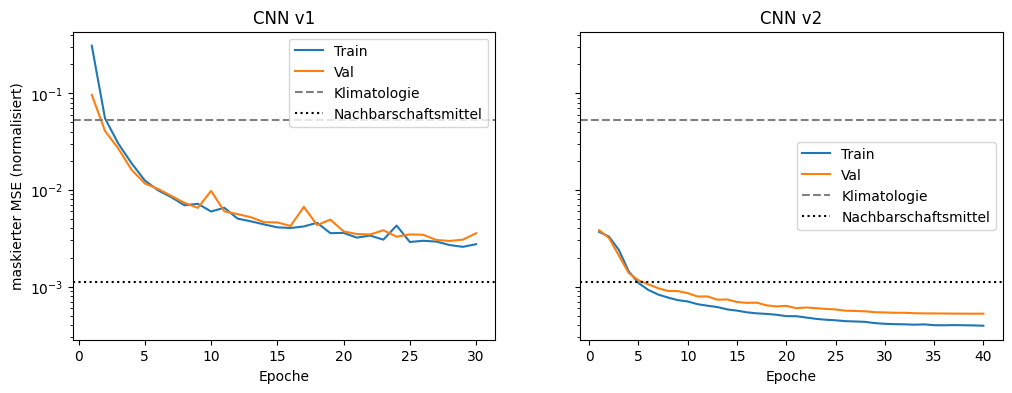

In [44]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True) #Legt die Form der Plots fest

for a, titel, tr, va in [(ax[0], "CNN v1", train_losses, val_losses),
                         (ax[1], "CNN v2", train_losses_v2, val_losses_v2)]:
    epochen = range(1, len(tr) + 1)
    a.plot(epochen, tr, label="Train")
    a.plot(epochen, va, label="Val")
    a.axhline(klim_loss, color="gray", linestyle="--", label="Klimatologie") #obere gestrichelte Linie zum Vergleich
    a.axhline(nach_loss, color="black", linestyle=":", label="Nachbarschaftsmittel") #untere gestrichelte Linie zum Vergleich
    a.set_yscale("log") #logarithmische Skala auf der y-Achse
    a.set_title(titel)
    a.set_xlabel("Epoche") #Innerhalb der for-Schleife, sodass sie in beiden Grafiken auftaucht
    a.legend()

ax[0].set_ylabel("maskierter MSE (normalisiert)") #gedreht, außerhalb der for-Schleife, sodass das nur einmal dransteht
plt.show()

fig.savefig("/content/drive/MyDrive/verlustkurven.png", dpi=150, bbox_inches="tight") #Speichern der Grafik für die README Datei

Nun können wir das Netz auf unseren Testdaten auswerten. Zur Vorbereitung, damit auch nichts schief geht, hier noch ein paar Tests:

In [45]:
!ls -la /content/drive/MyDrive | grep gapfill
print(mu_train, sd_train)
print(sst_test.shape, hidden_test.shape, sst_masked_test.shape)
float(hidden_test.where(ocean).mean())
float(hidden_test.where(ocean).mean())

-rw------- 1 root root   82593 Oct 12 16:31 gapfill_model.pt
-rw------- 1 root root   83787 Oct 12 16:33 gapfill_model_v2.pt
11.033391952514648 4.716279983520508
(364, 28, 48) (364, 28, 48) (364, 28, 48)


0.2999745287824758

Code für die Auswertung:

In [47]:
const = float(sst_train.mean())
model_v1 = model        # das gerade trainierte v1 (in der Trainingszelle heißt es "model")
# model_v2 existiert schon aus dem Training in dieser Sitzung

def nn_predict(model, X, mu, sd, like):
    model.eval()
    with torch.no_grad():
        out = model(X.to(device)).cpu().numpy()[:, 0] * sd + mu
    return xr.DataArray(out, coords=like.coords, dims=like.dims)

def predict_all(sst_masked_part, ocean, mu, sd, clim, const, model_v1, model_v2):
    md = sst_masked_part.time.dt.strftime("%m-%d")
    p_clim = clim.sel(md=md).drop_vars("md")
    p_nachbar = sst_masked_part.rolling(latitude=3, longitude=3, center=True, min_periods=1).mean().fillna(p_clim)
    return {
        "Konstant": xr.full_like(sst_masked_part, const),
        "Klimatologie": p_clim,
        "Nachbarschaftsmittel": p_nachbar,
        "CNN v1": nn_predict(model_v1, make_input(sst_masked_part, ocean, mu, sd), mu, sd, sst_masked_part),
        "CNN v2": nn_predict(model_v2, make_input_v2(sst_masked_part, ocean, mu, sd), mu, sd, sst_masked_part),
    }

def evaluate(preds, truth, hidden):
    return pd.Series({name: rmse(p, truth, hidden) for name, p in preds.items()}).sort_values()

preds_val = predict_all(sst_masked_val, ocean, mu_train, sd_train, clim, const, model_v1, model_v2)
print(evaluate(preds_val, sst_val, hidden_val).round(3))
print(results)          # die Tabelle aus diesem Lauf zum Vergleich

CNN v2                  0.108
Nachbarschaftsmittel    0.157
CNN v1                  0.282
Klimatologie            1.079
Konstant                4.901
dtype: float64
                                   Modell  RMSE Val 2021 [°C]  \
0                        CNN v2, Val 2021               0.108   
1          Nachbarschaftsmittel, Val 2021               0.157   
2                        CNN v1, Val 2021               0.282   
3                  Klimatologie, Val 2021               1.079   
4  konstanter Durchschnittswert, Val 2021               4.901   

   gegenüber Nachbarschaftsmittel [%]  
0                               -31.3  
1                                 0.0  
2                                79.0  
3                               585.9  
4                              3015.0  


Auswertung auf 2022:

Dieser Code darf nun nicht nochmal ausgeführt werden, da das Netz unsere Testdaten nun kennt und die neuen Ergebnisse dadurch verfälscht werden würden. Aus diesem Grund ist sie auskommentiert und die Ergebnisse aus dem ersten und einzigen Durchlauf sind im Text dadrunter noch einmal gespeichert.

In [48]:
#preds_test = predict_all(sst_masked_test, ocean, mu_train, sd_train, clim, const, model_v1, model_v2)
#res_test = evaluate(preds_test, sst_test, hidden_test)
#print(res_test.round(3))
#res_test.to_csv("/content/drive/MyDrive/ergebnisse_test_2022.csv")

CNN v2                  0.131
Nachbarschaftsmittel    0.194
CNN v1                  0.292
Klimatologie            1.056
Konstant                4.309
dtype: float64


Output (darf nur einmal ausgeführt werden):

CNN v2                  0.131

Nachbarschaftsmittel    0.194

CNN v1                  0.292

Klimatologie            1.056

Konstant                4.309

dtype: float64

In [49]:
torch.save(model_v1.state_dict(), "/content/drive/MyDrive/gapfill_model.pt")
torch.save(model_v2.state_dict(), "/content/drive/MyDrive/gapfill_model_v2.pt")

In [50]:
ref_t = res_test["Nachbarschaftsmittel"]
tab_test = pd.DataFrame({"RMSE Test 2022 [°C]": res_test,
                         "gegenüber Nachbarschaftsmittel [%]": (res_test / ref_t - 1) * 100})
tab_test = tab_test.round({"RMSE Test 2022 [°C]": 3, "gegenüber Nachbarschaftsmittel [%]": 1})
tab_test

,RMSE Test 2022 [°C],gegenüber Nachbarschaftsmittel [%]
CNN v2,0.131,-32.4
Nachbarschaftsmittel,0.194,0.0
CNN v1,0.292,50.2
Klimatologie,1.056,443.3
Konstant,4.309,2117.0
